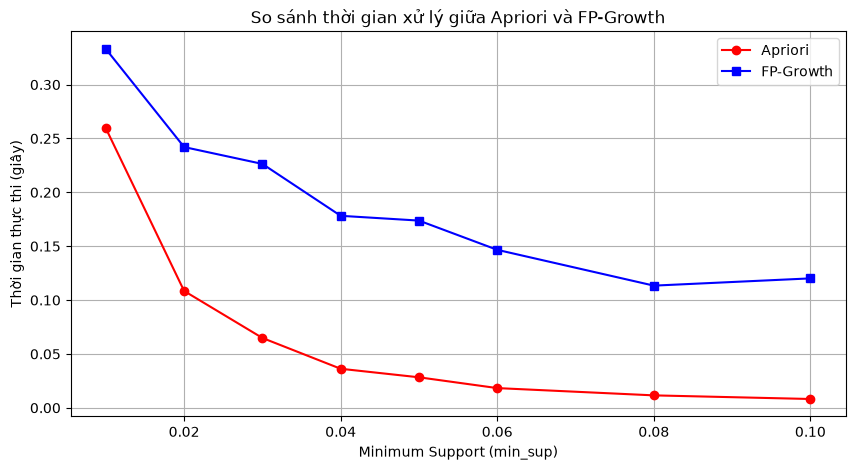

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

# 1. Đọc dữ liệu dạng danh sách các giao dịch (groceries.csv)
transactions = []
with open('groceries.csv', 'r') as f:
    for line in f:
        transaction = [item.strip() for item in line.strip().split(',') if item.strip()]
        if transaction:
            transactions.append(transaction)

# 2. Biến đổi dữ liệu thành One-Hot Encoding bằng TransactionEncoder
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_groceries = pd.DataFrame(te_ary, columns=te.columns_)

# 3. Các ngưỡng min_sup cần khảo sát (1% đến 10%)
min_sup_list = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10]
apriori_times = []
fpgrowth_times = []

for sup in min_sup_list:
    # Đo thời gian Apriori
    t0 = time.time()
    apriori(df_groceries, min_support=sup, use_colnames=True)
    t1 = time.time()
    apriori_times.append(t1 - t0)

    # Đo thời gian FP-Growth
    t0 = time.time()
    fpgrowth(df_groceries, min_support=sup, use_colnames=True)
    t1 = time.time()
    fpgrowth_times.append(t1 - t0)

# c) Vẽ biểu đồ so sánh thời gian xử lý
plt.figure(figsize=(10, 5))
plt.plot(min_sup_list, apriori_times, marker='o', label='Apriori', color='red')
plt.plot(min_sup_list, fpgrowth_times, marker='s', label='FP-Growth', color='blue')
plt.title('So sánh thời gian xử lý giữa Apriori và FP-Growth')
plt.xlabel('Minimum Support (min_sup)')
plt.ylabel('Thời gian thực thi (giây)')
plt.legend()
plt.grid(True)
plt.show()